<a href="https://colab.research.google.com/github/neha26-jpg/job-recommendation-system/blob/main/job_recommendationsystem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy scikit learn matplotlib seaborn

ERROR: Could not find a version that satisfies the requirement scikit (from versions: none)
ERROR: No matching distribution found for scikit


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns

In [ ]:
# Create job dataset

data = {
    "Job_ID": range(1, 16),

    "Job_Title": [
        "Data Analyst",
        "Python Developer",
        "Machine Learning Engineer",
        "Data Scientist",
        "Web Developer",
        "Business Analyst",
        "AI Engineer",
        "Software Developer",
        "Data Engineer",
        "Java Developer",
        "Power BI Developer",
        "NLP Engineer",
        "Cloud Engineer",
        "SQL Developer",
        "Automation Engineer"
    ],

    "Company": [
        "ABC Technologies",
        "Tech Solutions",
        "AI Innovations",
        "Data World",
        "Web Creators",
        "Business Corp",
        "Future AI",
        "Software Hub",
        "Cloud Data",
        "Java Systems",
        "Analytics Pro",
        "Language AI",
        "Cloud Systems",
        "Database Experts",
        "Auto Tech"
    ],

    "Skills": [
        "Python SQL Excel Power BI Pandas",
        "Python Django Flask SQL",
        "Python Machine Learning Deep Learning TensorFlow",
        "Python SQL Machine Learning Statistics Pandas",
        "HTML CSS JavaScript React",
        "Excel SQL Power BI Communication",
        "Python NLP Deep Learning Machine Learning",
        "Python Java SQL Data Structures",
        "Python SQL ETL Data Engineering",
        "Java Spring Boot SQL",
        "Power BI SQL Excel DAX",
        "Python NLP Transformers Deep Learning",
        "AWS Azure Docker Linux",
        "SQL PL SQL Database Oracle",
        "Python Selenium Automation Testing"
    ],

    "Location": [
        "Delhi", "Noida", "Bangalore", "Delhi",
        "Gurgaon", "Noida", "Bangalore", "Delhi",
        "Hyderabad", "Noida", "Delhi", "Bangalore",
        "Pune", "Delhi", "Gurgaon"
    ],

    "Experience": [
        "Fresher", "Fresher", "1-2 Years",
        "Fresher", "Fresher", "1-2 Years",
        "1-2 Years", "Fresher", "1-2 Years",
        "Fresher", "Fresher", "1-2 Years",
        "2-3 Years", "Fresher", "Fresher"
    ]
}

# Convert dictionary into DataFrame

jobs_df = pd.DataFrame(data)

# Display dataset

print(jobs_df)

    Job_ID                  Job_Title  ...   Location Experience
0        1               Data Analyst  ...      Delhi    Fresher
1        2           Python Developer  ...      Noida    Fresher
2        3  Machine Learning Engineer  ...  Bangalore  1-2 Years
3        4             Data Scientist  ...      Delhi    Fresher
4        5              Web Developer  ...    Gurgaon    Fresher
5        6           Business Analyst  ...      Noida  1-2 Years
6        7                AI Engineer  ...  Bangalore  1-2 Years
7        8         Software Developer  ...      Delhi    Fresher
8        9              Data Engineer  ...  Hyderabad  1-2 Years
9       10             Java Developer  ...      Noida    Fresher
10      11         Power BI Developer  ...      Delhi    Fresher
11      12               NLP Engineer  ...  Bangalore  1-2 Years
12      13             Cloud Engineer  ...       Pune  2-3 Years
13      14              SQL Developer  ...      Delhi    Fresher
14      15        Automat

In [ ]:
jobs_df.head()

,Job_ID,Job_Title,Company,Skills,Location,Experience
0,1,Data Analyst,ABC Technologies,Python SQL Excel Power BI Pandas,Delhi,Fresher
1,2,Python Developer,Tech Solutions,Python Django Flask SQL,Noida,Fresher
2,3,Machine Learning Engineer,AI Innovations,Python Machine Learning Deep Learning TensorFlow,Bangalore,1-2 Years
3,4,Data Scientist,Data World,Python SQL Machine Learning Statistics Pandas,Delhi,Fresher
4,5,Web Developer,Web Creators,HTML CSS JavaScript React,Gurgaon,Fresher


In [ ]:
print("Dataset Shape:", jobs_df.shape)

Dataset Shape: (15, 6)


In [ ]:
jobs_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Job_ID      15 non-null     int64 
 1   Job_Title   15 non-null     object
 2   Company     15 non-null     object
 3   Skills      15 non-null     object
 4   Location    15 non-null     object
 5   Experience  15 non-null     object
dtypes: int64(1), object(5)
memory usage: 852.0+ bytes


In [ ]:
print(jobs_df.isnull().sum())

Job_ID        0
Job_Title     0
Company       0
Skills        0
Location      0
Experience    0
dtype: int64


In [ ]:
print("Duplicate Record:", jobs_df.duplicated().sum())

Duplicate Record: 0


In [ ]:
# Create a copy of original dataset

jobs_df = jobs_df.copy()

# Remove duplicate records

jobs_df = jobs_df.drop_duplicates()

# Remove rows with missing job titles or skills

jobs_df = jobs_df.dropna(
    subset=["Job_Title", "Skills"]
)

# Clean text columns

jobs_df["Skills"] = (
    jobs_df["Skills"]
    .str.lower()
    .str.strip()
)

jobs_df["Job_Title"] = (
    jobs_df["Job_Title"]
    .str.strip()
)

jobs_df["Location"] = (
    jobs_df["Location"]
    .str.strip()
)

# Reset row index

jobs_df = jobs_df.reset_index(drop=True)

print("Dataset cleaned successfully!")
print(jobs_df.head())

Dataset cleaned successfully!
   Job_ID                  Job_Title  ...   Location Experience
0       1               Data Analyst  ...      Delhi    Fresher
1       2           Python Developer  ...      Noida    Fresher
2       3  Machine Learning Engineer  ...  Bangalore  1-2 Years
3       4             Data Scientist  ...      Delhi    Fresher
4       5              Web Developer  ...    Gurgaon    Fresher

[5 rows x 6 columns]


In [ ]:
# Count jobs by job title

job_counts = jobs_df["Job_Title"].value_counts()

print(job_counts)

Job_Title
Data Analyst                 1
Python Developer             1
Machine Learning Engineer    1
Data Scientist               1
Web Developer                1
Business Analyst             1
AI Engineer                  1
Software Developer           1
Data Engineer                1
Java Developer               1
Power BI Developer           1
NLP Engineer                 1
Cloud Engineer               1
SQL Developer                1
Automation Engineer          1
Name: count, dtype: int64


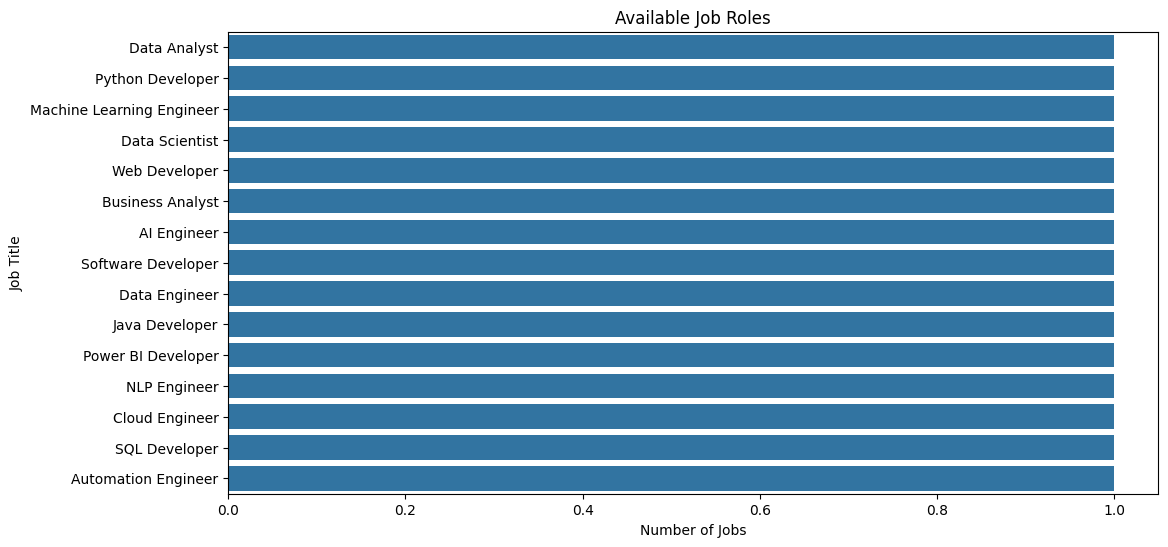

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=jobs_df,
    y="Job_Title",
    order=jobs_df["Job_Title"].value_counts().index
)

plt.title("Available Job Roles")
plt.xlabel("Number of Jobs")
plt.ylabel("Job Title")

plt.show()